# Same Page SC world model prototype

**What this notebook does**
1. Loads **real** student quiz logs (ASSISTments 2009–10 skill-builder, ~4,200 students).
2. Fits **Bayesian Knowledge Tracing (BKT)** per concept: how much students already know, how fast they learn, how often they guess or slip.
3. Fits a **population of learner types** (a nonparametric hierarchical model): how students differ in prior knowledge and learning speed.
4. Defines two **synthetic teaching patterns** (Section A: lecture-heavy, Section B: active learning), with teaching-move effects set from published research.
5. Runs **Monte Carlo semester rollouts** of 1,000+ synthetic students through each section.
6. Uses a **particle filter** to personalize the prediction for one real student, and outputs a fit range and predicted hard weeks.
7. Exports a JSON file the Next.js front end can read directly.

**Provenance labels used throughout** (every number is labeled):
- `[REAL-FIT]`: estimated from real student responses
- `[SYNTHETIC]`: invented for the demo (teaching patterns, course structure)
- `[ASSUMPTION]`: taken from published research, not fit to data yet; replaced by pilot data later

**A note on timestamps.** This ASSISTments release has response *order* and *response time* (`ms_first_response`) but not wall-clock time. So this notebook models learning order and fluency, but not forgetting-over-days or chronotype. EdNet (millisecond timestamps) is the dataset to add for those.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata

rng = np.random.default_rng(7)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL_A, COL_B = "#C2410C", "#1D4ED8"

DATA_URL = "https://raw.githubusercontent.com/CAHLR/pyBKT-examples/master/data/as.csv"
path = "data/as.csv" if os.path.exists("data/as.csv") else DATA_URL
raw = pd.read_csv(path, encoding="latin1", low_memory=False)
print(f"Loaded {len(raw):,} responses from {raw.user_id.nunique():,} students, {raw.skill_name.nunique()} skills")

Loaded 525,534 responses from 4,217 students, 110 skills


## 1. Build a mini course from real skills
The **skills and their responses are real**. The **course** (which skill is taught which week, and the prerequisite links) is `[SYNTHETIC]`: a 12-week quantitative-reasoning course with a midterm in week 6 and a final in week 12.

In [2]:
CONCEPTS = [
    "Ordering Fractions",                        # 0
    "Addition and Subtraction Fractions",        # 1
    "Conversion of Fraction Decimals Percents",  # 2
    "Percent Of",                                # 3
    "Proportion",                                # 4
    "Probability of a Single Event",             # 5
    "Probability of Two Distinct Events",        # 6
    "Venn Diagram",                              # 7
    "Equation Solving Two or Fewer Steps",       # 8
    "Finding Percents",                          # 9
]
PREREQS = {1: [0], 2: [0], 3: [2], 4: [1], 5: [2], 6: [5], 7: [5], 8: [4], 9: [3, 8]}   # [SYNTHETIC]
# Week -> concept index taught (None = exam week)
SCHEDULE = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: None, 7: 5, 8: 6, 9: 7, 10: 8, 11: 9, 12: None}
MIDTERM_CONCEPTS, FINAL_CONCEPTS = [0, 1, 2, 3, 4], list(range(10))
WEEKS = list(SCHEDULE)

df = raw[(raw.original == 1) & raw.skill_name.isin(CONCEPTS)].copy()
df = df[df.correct.isin([0, 1])].sort_values("order_id")
df["rt_s"] = df.ms_first_response / 1000.0
df["attempt_n"] = df.groupby(["user_id", "skill_name"]).cumcount() + 1
print(f"Course data: {len(df):,} responses, {df.user_id.nunique():,} students")
df.groupby("skill_name").agg(students=("user_id", "nunique"), responses=("correct", "size"),
                             pct_correct=("correct", "mean")).loc[CONCEPTS].round(2)

Course data: 130,528 responses, 3,239 students


,students,responses,pct_correct
skill_name,,,
Ordering Fractions,882,8539,0.79
Addition and Subtraction Fractions,1353,11334,0.68
Conversion of Fraction Decimals Percents,1225,20990,0.63
Percent Of,1115,22908,0.71
Proportion,756,9049,0.64
Probability of a Single Event,939,7029,0.76
Probability of Two Distinct Events,452,7453,0.50
Venn Diagram,552,18275,0.80
Equation Solving Two or Fewer Steps,961,17311,0.65


## 2. What response time adds `[REAL-FIT]`
Right/wrong alone says who knows what. **Response time** separates fluent answers from guesses and shows struggle before a student starts failing. Below: median response time by attempt number, and the share of wrong answers that were rapid guesses (under 5 seconds).

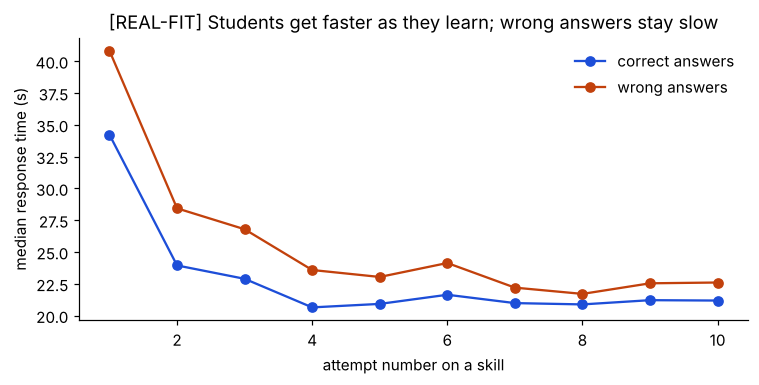

11.2% of wrong answers were given in under 5 s (likely guesses, not misconceptions)


In [3]:
d = df[(df.rt_s > 0) & (df.rt_s < 600) & (df.attempt_n <= 10)]
med = d.groupby(["attempt_n", "correct"]).rt_s.median().unstack()
rapid_wrong = ((d.rt_s < 5) & (d.correct == 0)).sum() / (d.correct == 0).sum()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(med.index, med[1], marker="o", color=COL_B, label="correct answers")
ax.plot(med.index, med[0], marker="o", color=COL_A, label="wrong answers")
ax.set(xlabel="attempt number on a skill", ylabel="median response time (s)",
       title="[REAL-FIT] Students get faster as they learn; wrong answers stay slow")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"{rapid_wrong:.1%} of wrong answers were given in under 5 s (likely guesses, not misconceptions)")

## 3. Fit BKT per concept `[REAL-FIT]`
BKT treats mastery as hidden. Each student starts mastered with probability **prior**, moves to mastered after each practice with probability **learn**, and answers with **guess** / **slip** noise. Fit by expectation–maximization on the first 40 attempts of each student on each skill. We hold out 20% of students to check prediction quality.

In [4]:
T_MAX = 40

def to_matrices(d):
    out = {}
    for skill, g in d.groupby("skill_name"):
        seqs = g.groupby("user_id", sort=True)["correct"].apply(lambda x: x.values[:T_MAX])
        N = len(seqs)
        O = np.zeros((N, T_MAX)); M = np.zeros((N, T_MAX), bool)
        for i, v in enumerate(seqs.values):
            O[i, :len(v)] = v; M[i, :len(v)] = True
        out[skill] = dict(O=O, M=M, users=seqs.index.values)
    return out

def emissions(O, M, guess, slip):
    e1 = np.where(O == 1, 1 - slip, slip); e0 = np.where(O == 1, guess, 1 - guess)
    return np.where(M, e1, 1.0), np.where(M, e0, 1.0)

def forward(O, M, prior, learn, guess, slip):
    """Returns per-sequence log-likelihood, and P(correct at t | answers before t).
    prior/learn may be arrays that broadcast against O.shape[:-1] (e.g. a grid of learner types)."""
    e1, e0 = emissions(O, M, guess, slip)
    T = O.shape[-1]
    pL = np.broadcast_to(prior, np.broadcast_shapes(np.shape(prior), O.shape[:-1])).astype(float)
    ll = 0.0; preds = []
    for t in range(T):
        preds.append(pL * (1 - slip) + (1 - pL) * guess)
        n1 = pL * e1[..., t]; n0 = (1 - pL) * e0[..., t]
        c = n1 + n0; ll = ll + np.log(c)
        post = n1 / c
        pL = post + (1 - post) * learn
    return ll, np.stack(preds, -1)

def fit_bkt(O, M, iters=80):
    prior, learn, guess, slip = 0.5, 0.15, 0.2, 0.1
    N, T = O.shape
    for _ in range(iters):
        e1, e0 = emissions(O, M, guess, slip)
        a1 = np.zeros((N, T)); a0 = np.zeros((N, T)); c = np.zeros((N, T))
        n1 = prior * e1[:, 0]; n0 = (1 - prior) * e0[:, 0]
        c[:, 0] = n1 + n0; a1[:, 0] = n1 / c[:, 0]; a0[:, 0] = n0 / c[:, 0]
        for t in range(1, T):
            n1 = (a1[:, t-1] + a0[:, t-1] * learn) * e1[:, t]
            n0 = a0[:, t-1] * (1 - learn) * e0[:, t]
            c[:, t] = n1 + n0; a1[:, t] = n1 / c[:, t]; a0[:, t] = n0 / c[:, t]
        b1 = np.ones((N, T)); b0 = np.ones((N, T))
        for t in range(T - 2, -1, -1):
            b1[:, t] = e1[:, t+1] * b1[:, t+1] / c[:, t+1]
            b0[:, t] = ((1 - learn) * e0[:, t+1] * b0[:, t+1] + learn * e1[:, t+1] * b1[:, t+1]) / c[:, t+1]
        g1 = a1 * b1; g0 = a0 * b0
        xi01 = a0[:, :-1] * learn * e1[:, 1:] * b1[:, 1:] / c[:, 1:]
        mt = M[:, 1:]
        prior = g1[:, 0].mean()
        learn = np.clip((xi01 * mt).sum() / (g0[:, :-1] * mt).sum(), 0.01, 0.6)
        guess = np.clip((g0 * O * M).sum() / (g0 * M).sum(), 0.01, 0.3)   # cap for identifiability
        slip = np.clip((g1 * (1 - O) * M).sum() / (g1 * M).sum(), 0.01, 0.3)
    return dict(prior=prior, learn=learn, guess=guess, slip=slip)

users = df.user_id.unique()
test_users = set(rng.choice(users, size=len(users) // 5, replace=False))
train = to_matrices(df[~df.user_id.isin(test_users)])
test = to_matrices(df[df.user_id.isin(test_users)])

PARAMS = {s: fit_bkt(train[s]["O"], train[s]["M"]) for s in CONCEPTS}
params_df = pd.DataFrame(PARAMS).T.loc[CONCEPTS].round(3)
params_df

,prior,learn,guess,slip
Ordering Fractions,0.748,0.101,0.300,0.109
Addition and Subtraction Fractions,0.746,0.099,0.126,0.192
Conversion of Fraction Decimals Percents,0.731,0.027,0.300,0.237
Percent Of,0.547,0.100,0.119,0.196
Proportion,0.587,0.058,0.300,0.203
Probability of a Single Event,0.870,0.124,0.115,0.175
Probability of Two Distinct Events,0.409,0.029,0.300,0.300
Venn Diagram,0.824,0.075,0.016,0.185
Equation Solving Two or Fewer Steps,0.648,0.044,0.275,0.251
Finding Percents,0.395,0.092,0.113,0.207


### Does it predict? (held-out students)
For every held-out answer, BKT predicts P(correct) from only that student's earlier answers. AUC 0.5 = coin flip; 1.0 = perfect. Baseline = each skill's overall percent correct.

In [5]:
def auc(y, p):
    r = rankdata(p); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

ys, ps, base = [], [], []
for s in CONCEPTS:
    O, M = test[s]["O"], test[s]["M"]; P = PARAMS[s]
    _, pred = forward(O, M, P["prior"], P["learn"], P["guess"], P["slip"])
    ys.append(O[M]); ps.append(pred[M]); base.append(np.full(M.sum(), train[s]["O"][train[s]["M"]].mean()))
ys, ps, base = map(np.concatenate, (ys, ps, base))
AUC_BKT, AUC_BASE = auc(ys, ps), auc(ys, base)
print(f"[REAL-FIT] Held-out AUC, BKT: {AUC_BKT:.3f}   skill-difficulty baseline: {AUC_BASE:.3f}   ({len(ys):,} answers)")

[REAL-FIT] Held-out AUC, BKT: 0.741   skill-difficulty baseline: 0.575   (21,351 answers)


## 4. Population of learner types `[REAL-FIT]`
Students differ. We give each student two personal knobs, applied on top of each concept's fitted BKT parameters:
- **prior offset** shifts how much they already know (on the log-odds scale)
- **learn multiplier** scales how fast they learn

A grid of 13 × 13 learner types is scored against every student's real answers, then a **nonparametric hierarchical model** (NPMLE via EM) estimates how common each type is. That distribution is what synthetic students are drawn from, and it's the starting belief for the particle filter.

**Reading the map:** three clusters show up in the real data: a large group of typical learners near the middle, a group that learns almost immediately (top row: at 8× the learning rate hits its ceiling, so "faster" is indistinguishable), and a group with low prior knowledge that barely moves within the practice window (bottom left). That last group is who Same Page SC most needs to flag early.

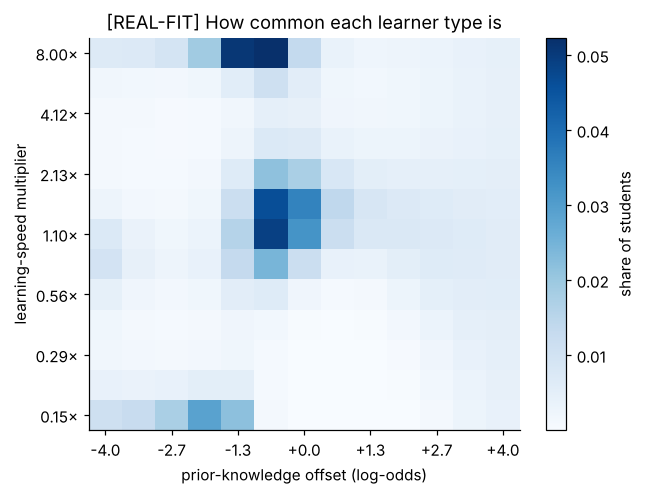

In [6]:
logit = lambda p: np.log(p / (1 - p)); sigmoid = lambda x: 1 / (1 + np.exp(-x))
OFFS = np.linspace(-4, 4, 13)
MULTS = np.exp(np.linspace(np.log(0.15), np.log(8), 13))
G_OFF, G_MULT = [a.ravel() for a in np.meshgrid(OFFS, MULTS, indexing="ij")]

all_m = to_matrices(df)
uidx = {u: i for i, u in enumerate(np.sort(df.user_id.unique()))}
LL = np.zeros((len(G_OFF), len(uidx)))
for s in CONCEPTS:
    P = PARAMS[s]; O, M = all_m[s]["O"], all_m[s]["M"]
    pr = sigmoid(logit(P["prior"]) + G_OFF)[:, None]
    le = np.clip(P["learn"] * G_MULT, 0, 0.95)[:, None]
    ll, _ = forward(O, M, pr, le, P["guess"], P["slip"])
    cols = np.array([uidx[u] for u in all_m[s]["users"]])
    np.add.at(LL, (slice(None), cols), ll)

pi = np.full(len(G_OFF), 1 / len(G_OFF))
for _ in range(300):
    lp = np.log(pi + 1e-300)[:, None] + LL
    lp -= lp.max(0); post = np.exp(lp); post /= post.sum(0)
    pi = post.mean(1)

fig, ax = plt.subplots(figsize=(6, 4.6))
im = ax.imshow(pi.reshape(13, 13).T, origin="lower", cmap="Blues", aspect="auto")
ax.set_xticks(range(0, 13, 2), [f"{v:+.1f}" for v in OFFS[::2]])
ax.set_yticks(range(0, 13, 2), [f"{v:.2f}×" for v in MULTS[::2]])
ax.set(xlabel="prior-knowledge offset (log-odds)", ylabel="learning-speed multiplier",
       title="[REAL-FIT] How common each learner type is")
plt.colorbar(im, ax=ax, label="share of students"); plt.tight_layout(); plt.show()

def sample_students(n, weights=pi, rng=rng):
    """Draw synthetic students from the fitted population (with jitter inside each grid cell)."""
    k = rng.choice(len(weights), size=n, p=weights / weights.sum())
    off = G_OFF[k] + rng.uniform(-1/3, 1/3, n)
    mult = G_MULT[k] * np.exp(rng.uniform(-0.165, 0.165, n))
    return off, mult

## 5. Two teaching patterns `[SYNTHETIC]` and move effects `[ASSUMPTION]`
Each week has 150 minutes of class, split across COPUS-style teaching moves. In a real deployment these minutes would come from observing the class. Here they're invented.

How each move turns into learning is `[ASSUMPTION]`, from the literature:
- **Explain** = baseline (weight 1).
- **Worked example** helps novices more than experts (expertise reversal, Kalyuga 2003): weight 1.5 for a student with no prior mastery, 0.5 for one with full mastery.
- **Question to class** and **think-pair-share** are active moves, weight `W_ACTIVE` (calibrated below). Questions only get full credit with ≥3 s wait time (Rowe's wait-time research).
- **Recap** has weight 0.5 and also slows forgetting.
- **Logistics** and **tangents** teach nothing.
- Learning a concept is slower when its prerequisites aren't mastered.

Then `SCALE` and `W_ACTIVE` are **calibrated so the simulation reproduces Freeman et al. 2014**: failure rates of 33.8% under traditional lecture vs. 21.8% under active learning.

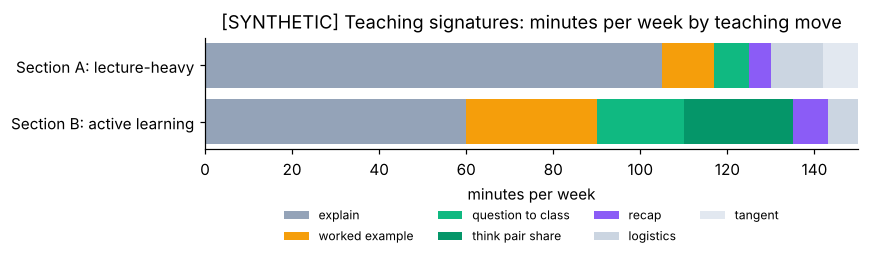

In [7]:
MOVES = ["explain", "worked_example", "question_to_class", "think_pair_share", "recap", "logistics", "tangent"]
SECTIONS = {
    "A": dict(label="Section A: lecture-heavy", wait_time_s=1.0,
              minutes=dict(explain=105, worked_example=12, question_to_class=8, think_pair_share=0,
                           recap=5, logistics=12, tangent=8)),
    "B": dict(label="Section B: active learning", wait_time_s=3.5,
              minutes=dict(explain=60, worked_example=30, question_to_class=20, think_pair_share=25,
                           recap=8, logistics=7, tangent=0)),
}
for k, s in SECTIONS.items(): assert sum(s["minutes"].values()) == 150, k

HOMEWORK_OPPS = 2       # [ASSUMPTION] practice problems per week outside class
FORGET = 0.05           # [ASSUMPTION] weekly decay of learned mastery; EdNet timestamps would let us fit this
ER = 0.5                # [ASSUMPTION] expertise-reversal strength
FAIL_BELOW = 0.60       # course score counted as D/F (Freeman's "failure")

fig, ax = plt.subplots(figsize=(8, 3.0))
left = np.zeros(2)
pal = ["#94A3B8", "#F59E0B", "#10B981", "#059669", "#8B5CF6", "#CBD5E1", "#E2E8F0"]
for m, c in zip(MOVES, pal):
    v = np.array([SECTIONS[k]["minutes"][m] for k in "AB"])
    ax.barh([1, 0], v, left=left, color=c, label=m.replace("_", " ")); left += v
ax.set_yticks([1, 0], [SECTIONS["A"]["label"], SECTIONS["B"]["label"]])
ax.set(xlabel="minutes per week", title="[SYNTHETIC] Teaching signatures: minutes per week by teaching move")
ax.legend(ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.42), loc="upper center")
plt.tight_layout(); plt.show()

In [8]:
def simulate(off, mult, sec, scale, w_active, sample=False, rng=rng):
    """Roll a batch of students through the 12-week course under one section's teaching pattern."""
    S, C = len(off), len(CONCEPTS)
    pr = np.array([PARAMS[c]["prior"] for c in CONCEPTS]); le = np.array([PARAMS[c]["learn"] for c in CONCEPTS])
    gu = np.array([PARAMS[c]["guess"] for c in CONCEPTS]); sl = np.array([PARAMS[c]["slip"] for c in CONCEPTS])
    start = sigmoid(logit(pr)[None, :] + off[:, None])
    p = start.copy()
    m = sec["minutes"]; q_eff = min(1.0, sec["wait_time_s"] / 3.0)
    f_eff = FORGET * max(0.0, 1 - 5 * m["recap"] / 150)
    covered = []
    mastery_curve = np.zeros((S, len(WEEKS))); assess = np.full((S, len(WEEKS)), np.nan)

    def score(idx, n_items):
        exp = p[:, idx] * (1 - sl[idx]) + (1 - p[:, idx]) * gu[idx]
        return (rng.binomial(n_items, exp) / n_items).mean(1) if sample else exp.mean(1)

    for wi, wk in enumerate(WEEKS):
        if covered:   # forgetting of earlier concepts
            cv = np.array(covered); p[:, cv] = start[:, cv] + (p[:, cv] - start[:, cv]) * (1 - f_eff)
        c = SCHEDULE[wk]
        if c is not None:
            pre = PREREQS.get(c, [])
            gate = 0.5 + 0.5 * p[:, pre].mean(1) if pre else 1.0
            learn = np.clip(le[c] * mult * gate, 0, 0.95)
            we_w = 1 + ER * (1 - 2 * p[:, c])
            dose = scale * (m["explain"] + m["worked_example"] * we_w + m["question_to_class"] * w_active * q_eff
                            + m["think_pair_share"] * w_active + m["recap"] * 0.5) / 150
            p[:, c] = 1 - (1 - p[:, c]) * (1 - learn) ** (dose + HOMEWORK_OPPS)
            covered.append(c)
            assess[:, wi] = score([c], 5)                    # weekly 5-question quiz
        elif wk == 6:
            assess[:, wi] = score(MIDTERM_CONCEPTS, 4)       # 20-question midterm
        else:
            assess[:, wi] = score(FINAL_CONCEPTS, 3)         # 30-question final
        mastery_curve[:, wi] = p[:, covered].mean(1)

    quiz_w = [i for i, w in enumerate(WEEKS) if SCHEDULE[w] is not None]
    course = 0.3 * np.nanmean(assess[:, quiz_w], 1) + 0.3 * assess[:, WEEKS.index(6)] + 0.4 * assess[:, WEEKS.index(12)]
    return dict(course=course, mastery=mastery_curve, assess=assess, final_mastery=p.mean(1))

# --- Calibrate SCALE and W_ACTIVE against Freeman 2014 ---
cal_off, cal_mult = sample_students(4000)
best = None
for scale in np.linspace(0.25, 8, 32):
    for w_act in np.linspace(1, 16, 31):
        fa = (simulate(cal_off, cal_mult, SECTIONS["A"], scale, w_act)["course"] < FAIL_BELOW).mean()
        fb = (simulate(cal_off, cal_mult, SECTIONS["B"], scale, w_act)["course"] < FAIL_BELOW).mean()
        err = (fa - 0.338) ** 2 + (fb - 0.218) ** 2
        if best is None or err < best[0]: best = (err, scale, w_act, fa, fb)
_, SCALE, W_ACTIVE, FA, FB = best
print(f"Calibrated SCALE={SCALE:.2f}, W_ACTIVE={W_ACTIVE:.2f}")
print(f"Simulated failure rate, A: {FA:.1%} (target 33.8%), B: {FB:.1%} (target 21.8%)")

Calibrated SCALE=2.00, W_ACTIVE=10.00
Simulated failure rate, A: 33.6% (target 33.8%), B: 22.0% (target 21.8%)


## 6. Monte Carlo semester rollouts
1,000 synthetic students from the fitted population go through each section. Bands show the middle 50% (25th–75th percentile) of average mastery on concepts covered so far.

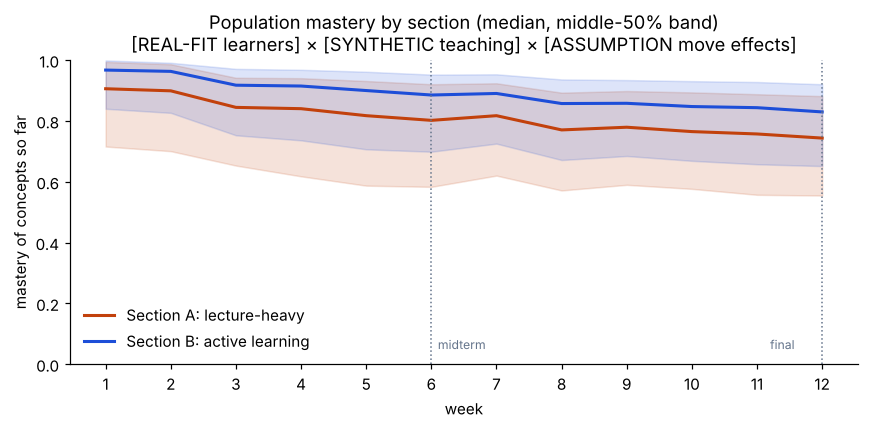

Average course-score gain from Section B over A, by prior knowledge:
low prior knowledge     +5.3%
middle                  +4.6%
high prior knowledge    +1.4%


In [9]:
N_SIM = 1000
off, mult = sample_students(N_SIM)
sim = {k: simulate(off, mult, SECTIONS[k], SCALE, W_ACTIVE, sample=True) for k in "AB"}

fig, ax = plt.subplots(figsize=(8, 4))
for k, col in zip("AB", (COL_A, COL_B)):
    q = np.percentile(sim[k]["mastery"], [25, 50, 75], axis=0)
    ax.fill_between(WEEKS, q[0], q[2], color=col, alpha=0.15)
    ax.plot(WEEKS, q[1], color=col, lw=2, label=SECTIONS[k]["label"])
for w in (6, 12): ax.axvline(w, color="#64748B", ls=":", lw=1)
ax.text(6.1, 0.05, "midterm", fontsize=8, color="#64748B"); ax.text(11.2, 0.05, "final", fontsize=8, color="#64748B")
ax.set(xlabel="week", ylabel="mastery of concepts so far", ylim=(0, 1), xticks=WEEKS,
       title="Population mastery by section (median, middle-50% band)\n[REAL-FIT learners] × [SYNTHETIC teaching] × [ASSUMPTION move effects]")
ax.legend(loc="lower left", framealpha=0.9, edgecolor="none"); plt.tight_layout(); plt.show()

# Who benefits most from the active section? Split by prior knowledge.
gain = sim["B"]["course"] - sim["A"]["course"]
tert = pd.qcut(off, 3, labels=["low prior knowledge", "middle", "high prior knowledge"])
print("Average course-score gain from Section B over A, by prior knowledge:")
print(pd.Series(gain).groupby(tert, observed=True).mean().map("{:+.1%}".format).to_string())

## 7. Personalize for one real student (particle filter)
Take a held-out **real** student's answers on the first three course concepts (as if from a prerequisite course or early quizzes). Start with 1,000 particles drawn from the population, weight each by how well it explains that student's real answers, and resample. Then roll the surviving particles through each section.

The result is what the registration screen shows: a **fit range**, not a single prediction, plus **weeks likely to be hard**.
(Ranges here are simulation percentiles. Once real outcomes exist, conformal prediction (MAPIE) recalibrates them so an "80% range" really covers 80% of students.)

Real student 79016: 53 answers on 3 concepts, 68% correct
Effective particles after update: 629 of 1000


Section A: lecture-heavy: predicted course score 56%–79% (median 71%), P(D/F) 15%, likely hard weeks: [3, 8, 10, 12]
Section B: active learning: predicted course score 63%–82% (median 74%), P(D/F) 6%, likely hard weeks: [8]


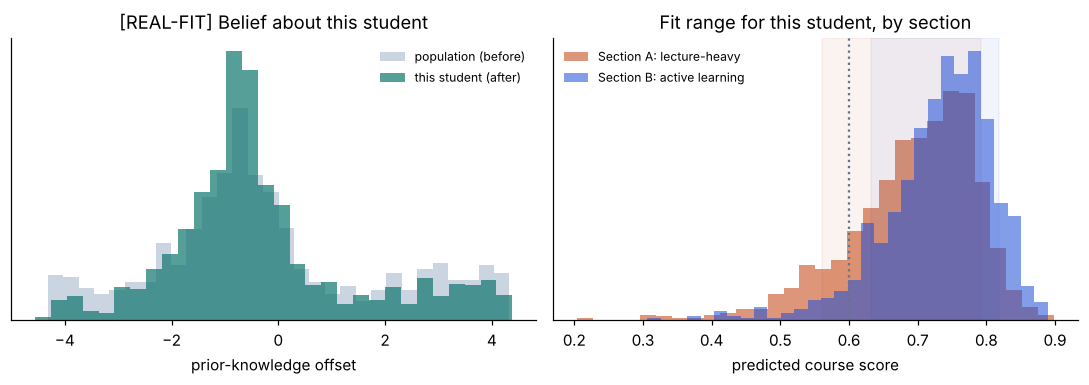

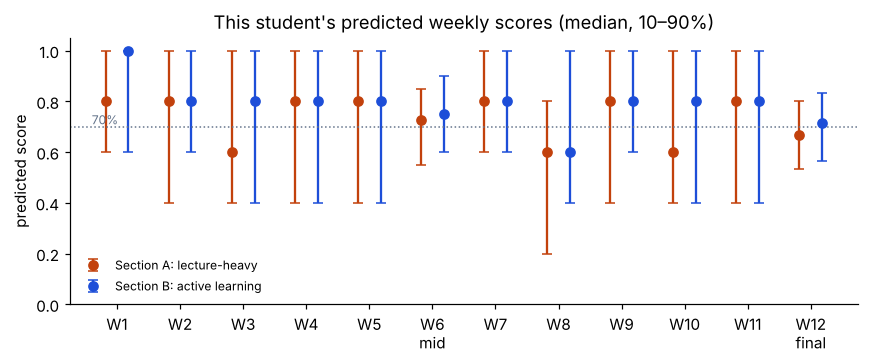

In [10]:
OBS_CONCEPTS = CONCEPTS[:3]
counts = df[df.user_id.isin(test_users) & df.skill_name.isin(OBS_CONCEPTS)].groupby("user_id").agg(
    n=("correct", "size"), k=("skill_name", "nunique"), acc=("correct", "mean"))
cands = counts[(counts.k == 3) & (counts.n >= 15)]
STUDENT = cands.sort_values("acc").index[len(cands) // 3] if len(cands) else counts.sort_values("n").index[-1]
stu = df[(df.user_id == STUDENT) & df.skill_name.isin(OBS_CONCEPTS)]
print(f"Real student {STUDENT}: {len(stu)} answers on {stu.skill_name.nunique()} concepts, {stu.correct.mean():.0%} correct")

N_PART = 1000
p_off, p_mult = sample_students(N_PART)
logw = np.zeros(N_PART)
for s in OBS_CONCEPTS:
    seq = stu[stu.skill_name == s].correct.values[:T_MAX]
    if len(seq) == 0: continue
    O = seq[None, :].astype(float); M = np.ones_like(O, bool); P = PARAMS[s]
    ll, _ = forward(O, M, sigmoid(logit(P["prior"]) + p_off)[:, None], np.clip(P["learn"] * p_mult, 0, 0.95)[:, None],
                    P["guess"], P["slip"])
    logw += ll[:, 0]
w = np.exp(logw - logw.max()); w /= w.sum()
ess = 1 / (w ** 2).sum()
keep = rng.choice(N_PART, size=N_PART, p=w)
post_off = p_off[keep] + rng.normal(0, 0.1, N_PART); post_mult = p_mult[keep] * np.exp(rng.normal(0, 0.05, N_PART))
print(f"Effective particles after update: {ess:.0f} of {N_PART}")

me = {k: simulate(post_off, post_mult, SECTIONS[k], SCALE, W_ACTIVE, sample=True) for k in "AB"}

def hard_weeks(res, thresh=0.70, prob=0.5):
    """Weeks where at least `prob` of this student's simulated futures score under `thresh` on that week's assessment."""
    return [wk for wi, wk in enumerate(WEEKS) if (res["assess"][:, wi] < thresh).mean() >= prob]

summary = {}
for k in "AB":
    lo, mid, hi = np.percentile(me[k]["course"], [10, 50, 90])
    summary[k] = dict(score_range=(lo, hi), median=mid, p_fail=(me[k]["course"] < FAIL_BELOW).mean(), hard=hard_weeks(me[k]))
    print(f"{SECTIONS[k]['label']}: predicted course score {lo:.0%}–{hi:.0%} (median {mid:.0%}), "
          f"P(D/F) {summary[k]['p_fail']:.0%}, likely hard weeks: {summary[k]['hard'] or 'none'}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.hist(p_off, bins=30, color="#CBD5E1", label="population (before)", density=True)
ax.hist(post_off, bins=30, color="#0F766E", alpha=0.7, label="this student (after)", density=True)
ax.set(xlabel="prior-knowledge offset", title="[REAL-FIT] Belief about this student", yticks=[]); ax.legend(frameon=False, fontsize=8)
ax = axes[1]
for k, col in zip("AB", (COL_A, COL_B)):
    ax.hist(me[k]["course"], bins=30, alpha=0.55, color=col, label=SECTIONS[k]["label"], density=True)
    lo, hi = summary[k]["score_range"]; ax.axvspan(lo, hi, color=col, alpha=0.06)
ax.axvline(FAIL_BELOW, color="#64748B", ls=":"); ax.set(xlabel="predicted course score", yticks=[],
       title="Fit range for this student, by section")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

# Weekly view: where this student is predicted to struggle
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, col, dx in zip("AB", (COL_A, COL_B), (-0.18, 0.18)):
    q = np.percentile(me[k]["assess"], [10, 50, 90], axis=0)
    ax.errorbar(np.array(WEEKS) + dx, q[1], yerr=[q[1] - q[0], q[2] - q[1]], fmt="o", color=col, capsize=3, label=SECTIONS[k]["label"])
ax.axhline(0.70, color="#64748B", ls=":", lw=1); ax.text(0.6, 0.71, "70%", fontsize=8, color="#64748B")
ax.set_xticks(WEEKS, [f"W{w}" + ("\nmid" if w == 6 else "\nfinal" if w == 12 else "") for w in WEEKS])
ax.set(ylabel="predicted score", ylim=(0, 1.05), title="This student's predicted weekly scores (median, 10–90%)")
ax.legend(frameon=False, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

## 8. Export for the front end
One JSON file with everything the registration and professor screens need, with provenance on every block.

In [11]:
def band(arr):
    q = np.percentile(arr, [10, 50, 90], axis=0)
    return [dict(week=int(w), p10=round(float(a), 3), p50=round(float(b), 3), p90=round(float(c), 3)) for w, a, b, c in zip(WEEKS, *q)]

out = dict(
    provenance=dict(
        product="Same Page SC",
        learner_model="REAL-FIT: BKT + NPMLE learner population fit on ASSISTments 2009-10 skill-builder",
        course_structure="SYNTHETIC", teaching_patterns="SYNTHETIC",
        move_effects="ASSUMPTION: literature priors, calibrated to Freeman et al. 2014 failure rates"),
    validation=dict(heldout_auc_bkt=round(float(AUC_BKT), 3), heldout_auc_baseline=round(float(AUC_BASE), 3)),
    calibration=dict(scale=round(float(SCALE), 3), w_active=round(float(W_ACTIVE), 3),
                     sim_fail_A=round(float(FA), 3), sim_fail_B=round(float(FB), 3), target_fail_A=0.338, target_fail_B=0.218),
    course=dict(weeks=[dict(week=w, concept=(CONCEPTS[c] if c is not None else ("Midterm" if w == 6 else "Final")),
                            prereqs=[CONCEPTS[p] for p in PREREQS.get(c, [])] if c is not None else []) for w, c in SCHEDULE.items()]),
    sections={k: dict(label=SECTIONS[k]["label"], wait_time_s=SECTIONS[k]["wait_time_s"], minutes_per_week=SECTIONS[k]["minutes"],
                      population_mastery=band(sim[k]["mastery"]), population_fail_rate=round(float((sim[k]["course"] < FAIL_BELOW).mean()), 3),
                      student=dict(score_p10=round(float(summary[k]["score_range"][0]), 3), score_p50=round(float(summary[k]["median"]), 3),
                                   score_p90=round(float(summary[k]["score_range"][1]), 3), p_fail=round(float(summary[k]["p_fail"]), 3),
                                   hard_weeks=summary[k]["hard"], weekly_scores=band(me[k]["assess"])))
              for k in "AB"},
    student=dict(source="REAL: held-out ASSISTments student (anonymous id)", id=int(STUDENT),
                 observed_answers=int(len(stu)), observed_accuracy=round(float(stu.correct.mean()), 3), effective_particles=int(ess)),
)
os.makedirs("output", exist_ok=True)
with open("output/same_page_sc_sim_output.json", "w") as f: json.dump(out, f, indent=2)
print("Wrote output/same_page_sc_sim_output.json")

Wrote output/same_page_sc_sim_output.json
